# Modelo de traslado

Cuanto de una suba de precios mayoristas llega a la gondola y en cuantos meses.

Como se estima (el codigo esta en `src/monitor/traslado.py`):

- Todo en variaciones log **relativas**: a la gondola le resto la inflacion general de su region y al mayorista la del mayorista. En el EDA se vio que sin esto el modelo mide la inflacion y no el traslado.
- Para cada rubro y region un modelo de rezagos distribuidos: la gondola de este mes contra el mayorista de este mes y de los 3 anteriores, mas 2 meses de la propia gondola. Los rezagos son fijos y no los elige el BIC: con series simuladas de traslado conocido, elegir y estimar con los mismos datos daba intervalos que cubrian 84% en vez de 95% (ver `tests/test_traslado.py`).
- **Traslado de largo plazo** = suma de los coeficientes del mayorista / (1 - suma de los de la gondola). 1 es traslado completo, 0 nada. El intervalo sale por metodo delta con errores HC3 (robustos a que la volatilidad cambie entre etapas) y valores de la t.
- Son mas de 100 estimaciones, asi que la significancia se corrige por comparaciones multiples (Benjamini-Hochberg). En gris lo que no pasa.
- Es un modelo de prediccion, no causal: dice cuanto acompana la gondola al mayorista, no que una cosa cause la otra.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from monitor import analisis as a
from monitor import traslado as t

a.estilo()
con = a.conectar()
nombres = a.nombres_rubros(con)

resultados = t.estimar_todo(con)
industria = resultados[resultados.etapa == "industria"]
gba = industria[industria.region == "GBA"].set_index("par_id").rename(index=nombres)
print(f"{len(resultados)} estimaciones, {resultados.significativo_fdr.sum()} significativas")

132 estimaciones, 75 significativas


## 1. Cuanto se traslada (GBA)

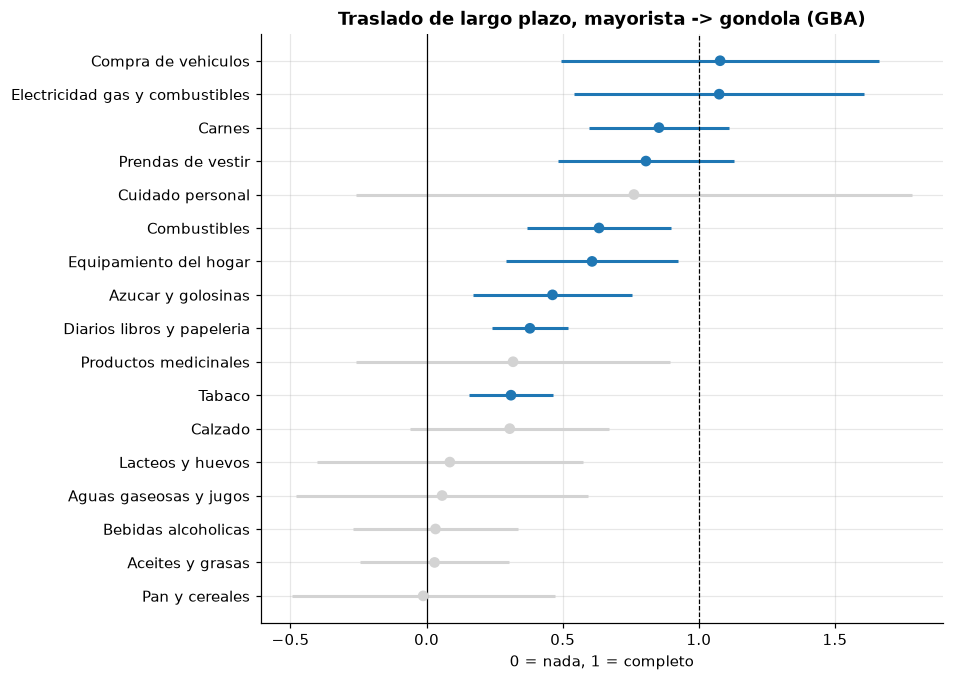

In [2]:
ax = a.intervalos(gba, "Traslado de largo plazo, mayorista -> gondola (GBA)")
ax.set_xlabel("0 = nada, 1 = completo")
plt.show()

In [3]:
cols = [
    "impacto",
    "mes_1",
    "mes_2",
    "mes_3",
    "largo_plazo",
    "ic_inf",
    "ic_sup",
    "significativo_fdr",
]
gba.sort_values("largo_plazo", ascending=False)[cols].round(2)

,impacto,mes_1,mes_2,mes_3,largo_plazo,ic_inf,ic_sup,significativo_fdr
par_id,,,,,,,,
Compra de vehiculos,0.76,0.02,0.19,0.18,1.08,0.49,1.66,True
Electricidad gas y combustibles,0.55,0.21,0.38,-0.04,1.07,0.54,1.61,True
Carnes,0.58,0.12,0.09,0.04,0.85,0.60,1.11,True
Prendas de vestir,0.36,0.10,0.22,-0.00,0.81,0.48,1.13,True
Cuidado personal,0.45,0.19,-0.05,0.08,0.76,-0.26,1.78,False
Combustibles,0.70,0.04,0.11,-0.15,0.63,0.37,0.90,True
Equipamiento del hogar,0.11,0.22,0.25,0.03,0.61,0.29,0.92,True
Azucar y golosinas,0.16,0.03,0.04,0.14,0.46,0.17,0.76,True
Diarios libros y papeleria,0.22,0.02,0.11,0.14,0.38,0.24,0.52,True


`impacto` es lo que llega en el mismo mes y `mes_1` a `mes_3` lo que se suma en cada mes siguiente.

- Carnes y prendas trasladan mas de 0.8, combustibles 0.6. Autos da arriba de 1 pero con un intervalo enorme (0.5 a 1.7).
- Cuando llega: en los rubros significativos, en la mediana el 60% llega en el mismo mes y casi 70% en los dos primeros. Combustibles es casi todo inmediato; en autos, prendas y equipamiento del hogar una parte llega 2 o 3 meses despues.
- Tabaco tenia una correlacion alta en el EDA y aca traslada 0.31: se mueven juntos, pero el mayorista se mueve mucho mas. Correlacion y traslado no son lo mismo.
- Lacteos, pan, aceites, bebidas, calzado, medicamentos y cuidado personal no dan significativos. En cuidado personal el punto es alto (0.76) pero el intervalo va de -0.3 a 1.8: no alcanza para decir nada. En aceites y aguas, gaseosas y jugos puede ser que la correspondencia entre codigos no sea buena.
- Energia da arriba de 1, pero es tarifa regulada: no es traslado de mercado, queda como contraste.

## 2. Por region

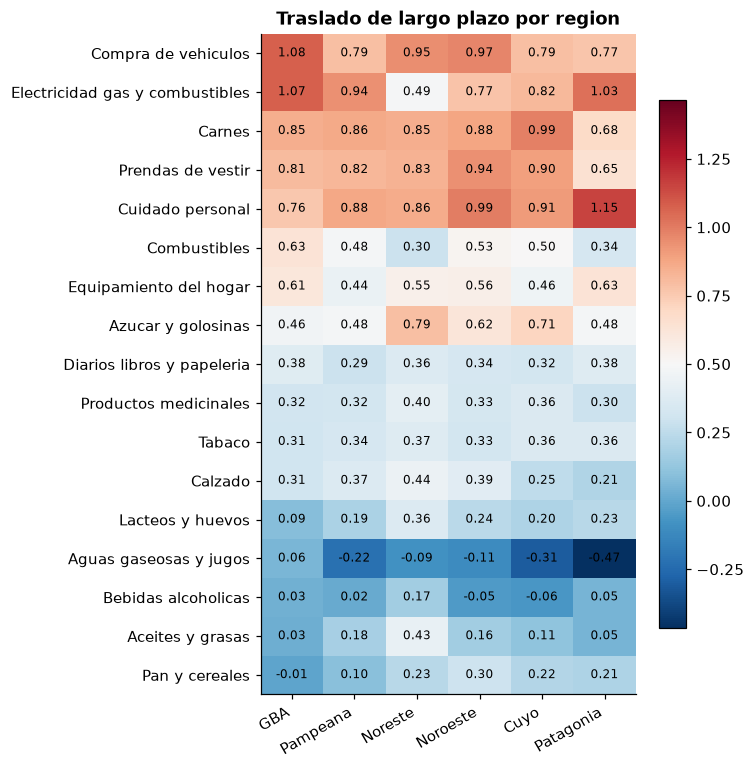

In [4]:
por_region = industria.pivot(index="par_id", columns="region", values="largo_plazo")[a.REGIONES]
a.mapa_calor(
    por_region.rename(index=nombres).sort_values("GBA", ascending=False),
    "Traslado de largo plazo por region",
    centro=0.5,
    rotar=30,
)
plt.show()

- En la mayoria de los rubros las regiones dan parecido. Carnes y prendas trasladan parecido en todo el pais, algo menos en Patagonia.
- Combustibles traslada bastante menos en el Noreste y en Patagonia (0.3) que en GBA (0.6), y autos algo menos en el interior.
- Lacteos, azucar y golosinas y pan trasladan mas en el interior que en GBA.

## 3. Segun el nivel de inflacion

Mismos rezagos que con toda la muestra, estimado por separado en cada etapa: baja (2017 y 2025-26), media (2018-21) y alta (2022-24). Cada etapa tiene entre 2 y 4 anios de datos, asi que los intervalos son anchos y lo que importa es la tendencia.

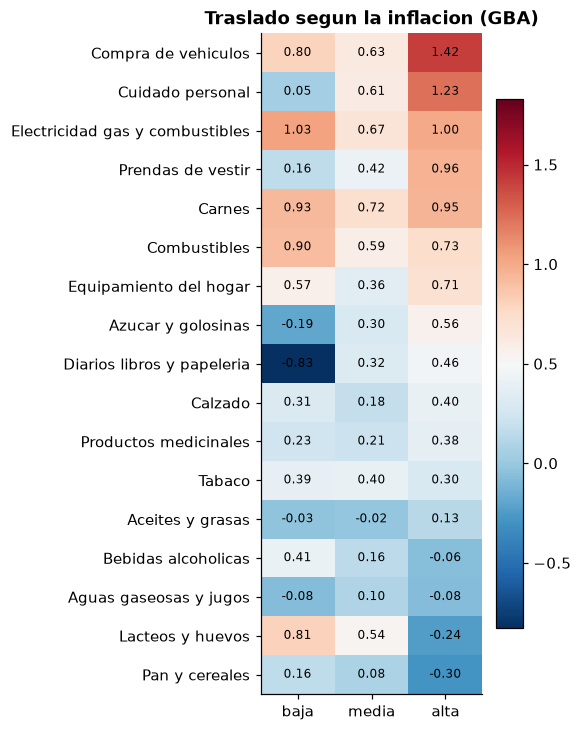

rubros donde traslada mas con inflacion alta que baja: 10 de 17


In [5]:
gondola, mayorista = t.datos_modelo(con)
g, m = gondola["GBA"], mayorista["industria"]
por_regimen = pd.DataFrame(
    [
        {"par_id": r} | fila
        for r in g.columns.intersection(m.columns)
        for fila in t.estimar_por_regimen(g[r], m[r], r in t.ESTACIONALES)
    ]
)
tabla_reg = por_regimen.pivot(index="par_id", columns="regimen", values="largo_plazo")
tabla_reg = tabla_reg[["baja", "media", "alta"]].rename(index=nombres)
a.mapa_calor(
    tabla_reg.sort_values("alta", ascending=False), "Traslado segun la inflacion (GBA)", centro=0.5
)
plt.show()

print(
    "rubros donde traslada mas con inflacion alta que baja:",
    (tabla_reg.alta > tabla_reg.baja).sum(),
    "de",
    len(tabla_reg),
)

En 10 de los 17 rubros el traslado es mas alto con inflacion alta que con baja. Tiene logica: con inflacion alta los precios se actualizan mas seguido y las empresas trasladan mas rapido y mas completo. Prendas, cuidado personal y autos son los casos mas claros. Lacteos y pan van al reves.

## 4. Como cambio en el tiempo

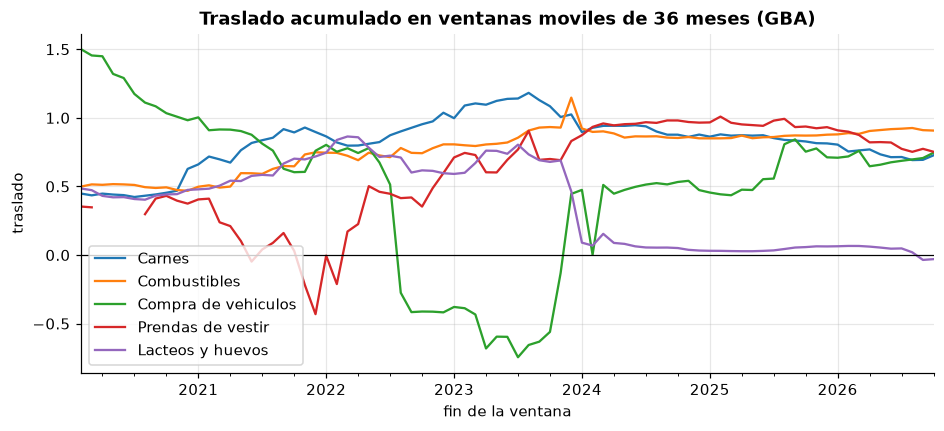

In [6]:
movil = pd.DataFrame(
    {
        r: t.traslado_movil(g[r], m[r])
        for r in ["carnes", "combustibles", "autos", "prendas", "lacteos"]
    }
).rename(columns=nombres)

ax = movil.plot(figsize=(10, 4))
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Traslado acumulado en ventanas moviles de 36 meses (GBA)")
ax.set_ylabel("traslado")
ax.set_xlabel("fin de la ventana")
plt.show()

Cada punto es el traslado estimado con los 36 meses anteriores.

- Carnes, combustibles y prendas suben en las ventanas que agarran 2022-2024 y despues se quedan cerca de 0.8-0.9.
- Autos es muy inestable: en ventanas que terminan en 2022-2023 llega a dar negativo. Su numero de toda la muestra hay que tomarlo con cuidado.
- Lacteos casi desaparece desde 2024.

## 5. La cadena completa: productor -> industria -> gondola

Para carnes, lacteos y pan hay precio del productor agropecuario. Un VAR con las tres etapas (en ese orden) muestra cuanto se mueve la gondola, acumulado, despues de una suba de 1 en el productor o en la industria.

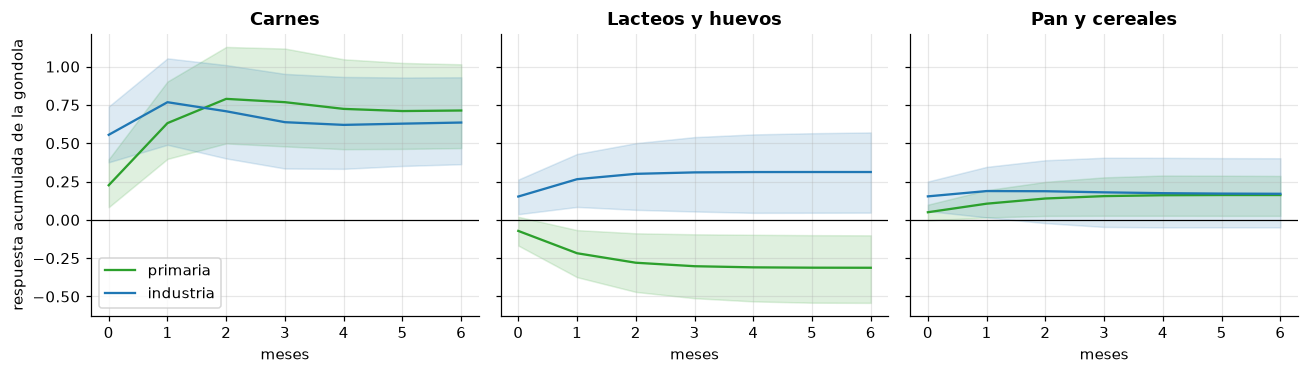

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, rubro in zip(axes, t.CADENA, strict=True):
    resp, _ = t.cadena(mayorista["primaria"][rubro], m[rubro], g[rubro])
    for origen, color in [("primaria", "tab:green"), ("industria", "tab:blue")]:
        d = resp[resp.origen == origen]
        ax.plot(d.mes, d.respuesta, color=color, label=origen)
        ax.fill_between(d.mes, d.ic_inf, d.ic_sup, color=color, alpha=0.15)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(nombres[rubro])
    ax.set_xlabel("meses")
axes[0].set_ylabel("respuesta acumulada de la gondola")
axes[0].legend()
plt.tight_layout()
plt.show()

- Carnes es la cadena mas clara: una suba en el frigorifico llega a la gondola casi toda en el primer mes; una suba del ganado tarda unos 2 meses.
- Pan y cereales: llega poco de las dos etapas.
- Lacteos da negativo desde el productor. El codigo del productor (0121) mezcla ganado vacuno con leche y seguramente lo mueve mas la carne que la leche. No lo tomaria como resultado.

## 6. Chequeos

- **Otro indice mayorista.** Con el IPIB (sin impuestos) en vez del IPIM:

In [8]:
ipib = t.estimar_todo(con, "IPIB")
ipib_gba = ipib[(ipib.region == "GBA") & (ipib.etapa == "industria")].set_index("par_id")
comp = pd.DataFrame({"IPIM": gba.largo_plazo, "IPIB": ipib_gba.largo_plazo.rename(index=nombres)})
print("correlacion:", round(comp.corr().iloc[0, 1], 3))
comp[(comp.IPIM - comp.IPIB).abs() > 0.02].round(2)

correlacion: 0.994


,IPIM,IPIB
par_id,,
Combustibles,0.63,0.79
Tabaco,0.31,0.26


Da practicamente igual. Solo cambian tabaco y combustibles, que son justo los rubros con impuestos pesados.

- **Residuos.** Con Ljung-Box (6 rezagos) quedan con autocorrelacion:

In [9]:
mal = gba[gba.p_ljungbox < 0.05]
mal[["rezagos_x", "rezagos_y", "p_ljungbox"]].round(3)

,rezagos_x,rezagos_y,p_ljungbox
par_id,,,
Cuidado personal,3,2,0.018
Lacteos y huevos,3,2,0.024
Diarios libros y papeleria,3,2,0.025


Son cuidado personal, lacteos y libreria. Los errores HC3 cubren que la volatilidad cambie, no autocorrelacion que quede en los residuos: en esos tres el modelo no captura toda la dinamica y conviene tomarlos con mas cuidado.

## Resumen

- La mayor parte de una suba mayorista llega a la gondola **en el mismo mes** (60% en la mediana) y el resto se reparte en los 3 meses siguientes.
- Lo que cambia mucho es **cuanto** llega: mas de 0.8 en carnes y prendas, 0.6 en combustibles y equipamiento del hogar, nada que se pueda distinguir de cero en lacteos, aceites, pan o bebidas.
- De 132 estimaciones (rubro x region x etapa), 75 son significativas despues de corregir por comparaciones multiples.
- Con **inflacion alta se traslada mas** en 10 de 17 rubros.
- Entre regiones las diferencias son chicas, salvo combustibles y autos.

Limites: el modelo es de asociacion, no de causalidad; la correspondencia mayorista-IPC es aproximada en algunos rubros; y con 2 a 4 anios por regimen los intervalos son anchos.